# 01 ETL and data quality

**Business question.** The internal audit office reviews every accounts-payable (AP) voucher and purchasing-card (P-card) transaction for signs of error, waste or fraud. Before any test can be trusted, the ledger extracts have to be loaded into one consistent, validated store. This notebook runs the ETL pipeline in `src/etl.py`:

1. **Extract** the three fiscal-year transaction extracts (FY2023 to FY2025) and the master files (vendors, departments, employees, GL accounts, university holidays).
2. **Validate** every row against data-quality rules. Fixable defects (whitespace, letter case in keys) are corrected; rows that cannot be trusted (missing amount or approver, unparseable dates, unknown vendor) are quarantined with a reason instead of being silently dropped, so the audit trail stays complete.
3. **Load** the clean rows into SQLite and create the SQL views that the anomaly checks run on.

The data is synthetic (see the README); the generator plants nine kinds of anomalies whose labels are used only in notebook 02 for evaluation.

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
RAW, PROC, FIG = Path("../data/raw"), Path("../data/processed"), Path("../reports/figures")
PROC.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight",
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=["#2a6fb0", "#e0702b", "#2e9e6b", "#c9a227", "#8a5cc2", "#d0475a", "#5a6b7b", "#3fb3c4"]),
})

## 1. Run the pipeline

`run_etl` returns the data-quality log and stage timings. The SQLite database is written to `data/warehouse/audit.db` (not committed; it is rebuilt in seconds).

In [2]:
from etl import run_etl, connect, DB_PATH

etl = run_etl()
print(f"rows extracted : {etl.rows_extracted:,}")
print(f"rows loaded    : {etl.rows_loaded:,}")
print(f"rows rejected  : {etl.rows_rejected:,}")
print("stage timings (s):", {k: round(v, 2) for k, v in etl.timings.items()})

rows extracted : 418,070
rows loaded    : 417,470
rows rejected  : 260
stage timings (s): {'extract_s': 0.99, 'validate_s': 2.84, 'load_s': 2.32, 'total_s': 6.16}


## 2. Data-quality log

Each rule, how many rows it touched, and what the pipeline did about it.

In [3]:
dq = etl.dq_report
dq[dq.rows_affected > 0]

,rule,rows_affected,action
0,rows extracted,418070,-
1,vendor_id: whitespace / case standardised,2000,fixed
2,exact duplicate records,340,removed
3,missing or non-numeric amount,60,quarantined
4,unparseable posting date,60,quarantined
6,missing approver,80,quarantined
7,unknown vendor id,60,quarantined
13,rows passed to load,417470,-


## 3. Reconciliation

An ETL that loses rows silently is worse than no ETL. Every extracted row must be accounted for as loaded, quarantined, or removed as an exact duplicate extract record, and the dollar total of loaded plus quarantined rows must tie back to the raw files.

In [4]:
conn = connect(DB_PATH)
raw = pd.concat([pd.read_csv(f, dtype=str, keep_default_na=False) for f in sorted(RAW.glob("transactions_FY*.csv"))])
removed_dups = int(dq.loc[dq.rule == "exact duplicate records", "rows_affected"].iloc[0])

loaded = pd.read_sql_query("SELECT COUNT(*) n, SUM(amount) amt FROM transactions", conn).iloc[0]
rej = pd.read_sql_query("SELECT * FROM rejected_transactions", conn)

raw_dedup = raw.drop_duplicates()
raw_amt = pd.to_numeric(raw_dedup["amount"], errors="coerce").sum()
rej_amt = pd.to_numeric(rej["amount"], errors="coerce").sum()

recon = pd.DataFrame({
    "rows": [len(raw), int(loaded.n), len(rej), removed_dups, len(raw) - int(loaded.n) - len(rej) - removed_dups],
    "amount_usd": [raw_amt, loaded.amt, rej_amt, np.nan, raw_amt - loaded.amt - rej_amt],
}, index=["raw extract", "loaded", "quarantined", "exact duplicates removed", "unexplained difference"])
recon.style.format({"rows": "{:,.0f}", "amount_usd": "${:,.2f}"})

,rows,amount_usd
raw extract,"418,070","$830,979,152.40"
loaded,"417,470","$830,945,745.16"
quarantined,260,"$33,407.24"
exact duplicates removed,340,$nan
unexplained difference,0,$0.00


In [5]:
rej.groupby("reject_reason").size().rename("rows").to_frame()

,rows
reject_reason,
missing approver,80
missing or non-numeric amount,60
unknown vendor id,60
unparseable posting date,60


## 4. Integrity checks on the loaded table

Primary-key uniqueness, nulls in required fields and date ranges, checked with SQL against the loaded data.

In [6]:
integrity = pd.read_sql_query("""
SELECT
  COUNT(*)                                            AS rows_loaded,
  COUNT(DISTINCT txn_id)                              AS distinct_txn_ids,
  SUM(amount IS NULL)                                 AS null_amounts,
  SUM(approver_id IS NULL OR approver_id = '')        AS missing_approvers,
  MIN(posting_date)                                   AS first_posting,
  MAX(posting_date)                                   AS last_posting,
  SUM(source = 'AP')                                  AS ap_rows,
  SUM(source = 'PCARD')                               AS pcard_rows,
  SUM(amount < 0)                                     AS credit_memos
FROM transactions""", conn).T.rename(columns={0: "value"})
integrity

,value
rows_loaded,417470
distinct_txn_ids,417470
null_amounts,0
missing_approvers,0
first_posting,2022-07-02
last_posting,2025-06-30
ap_rows,228905
pcard_rows,188565
credit_memos,2339


## 5. Profile of the validated ledger

Scale of the population the checks will cover: rows and dollars by fiscal year and source.

In [7]:
prof = pd.read_sql_query("""
SELECT fiscal_year, source, COUNT(*) AS transactions, ROUND(SUM(amount), 0) AS amount_usd,
       ROUND(AVG(amount), 2) AS mean_amount
FROM transactions GROUP BY fiscal_year, source ORDER BY fiscal_year, source""", conn)
total = prof[["transactions", "amount_usd"]].sum()
print(f"Total: {int(total.transactions):,} transactions, ${total.amount_usd:,.0f}")
prof.style.format({"transactions": "{:,.0f}", "amount_usd": "${:,.0f}", "mean_amount": "${:,.2f}"})

Total: 417,470 transactions, $830,945,746


,fiscal_year,source,transactions,amount_usd,mean_amount
0,2023,AP,"69,897","$235,395,608","$3,367.75"
1,2023,PCARD,"63,119","$12,451,906",$197.28
2,2024,AP,"76,302","$260,301,795","$3,411.47"
3,2024,PCARD,"63,585","$12,687,518",$199.54
4,2025,AP,"82,706","$297,860,314","$3,601.44"
5,2025,PCARD,"61,861","$12,248,605",$198.00


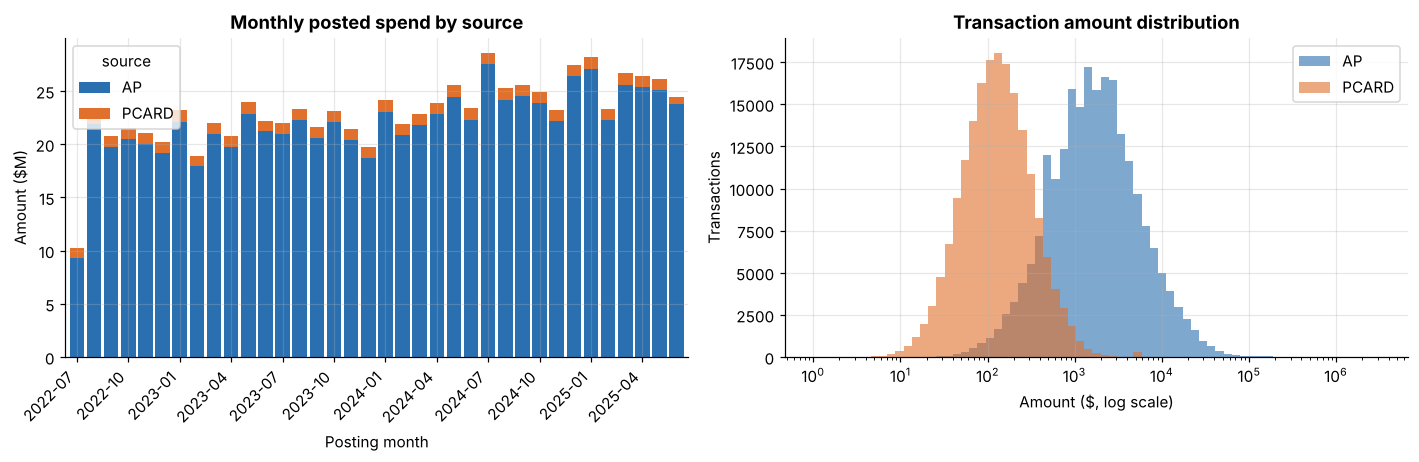

In [8]:
monthly = pd.read_sql_query("""
SELECT substr(posting_date, 1, 7) AS month, source, SUM(amount) / 1e6 AS amount_m, COUNT(*) AS n
FROM transactions GROUP BY 1, 2 ORDER BY 1""", conn)
piv = monthly.pivot(index="month", columns="source", values="amount_m")
amts = pd.read_sql_query("SELECT source, amount FROM transactions WHERE amount > 0", conn)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
piv.plot.bar(stacked=True, ax=axes[0], width=0.85)
axes[0].set_title("Monthly posted spend by source")
axes[0].set_xlabel("Posting month"); axes[0].set_ylabel("Amount ($M)")
ticks = range(0, len(piv), 3)
axes[0].set_xticks(list(ticks)); axes[0].set_xticklabels(piv.index[list(ticks)], rotation=45, ha="right")
bins = np.logspace(0, 6.5, 70)
for src, g in amts.groupby("source"):
    axes[1].hist(g.amount, bins=bins, alpha=0.6, label=src)
axes[1].set_xscale("log"); axes[1].set_title("Transaction amount distribution")
axes[1].set_xlabel("Amount ($, log scale)"); axes[1].set_ylabel("Transactions"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "01_ledger_profile.png"); plt.show()

In [9]:
top_dept = pd.read_sql_query("""
SELECT dept_name, COUNT(*) AS transactions, ROUND(SUM(amount) / 1e6, 1) AS amount_m
FROM v_txn GROUP BY dept_name ORDER BY amount_m DESC LIMIT 10""", conn)
top_dept

,dept_name,transactions,amount_m
0,Information Technology,34696,69.4
1,Housing & Residence Life,34935,68.7
2,Campus Dining,23198,46.0
3,Facilities Management,22442,43.8
4,Athletics,20955,41.6
5,Medicine Research Labs,20376,41.3
6,Mathematics,16848,33.5
7,Admissions,16804,32.8
8,Campus Police,16435,32.6
9,Communications & Marketing,14991,29.2


## 6. SQL views available to the checks

Seven checks are implemented as SQL views (`src/sql/views.sql`); the Benford and vendor z-score checks are statistical tests in Python on top of the same tables.

In [10]:
views = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type = 'view' ORDER BY name", conn)
views["rows"] = [pd.read_sql_query(f"SELECT COUNT(*) n FROM {v}", conn).n.iloc[0] for v in views.name]
views

,name,rows
0,v_chk_duplicate_payments,592
1,v_chk_new_vendor_large,154
2,v_chk_round_dollar,6335
3,v_chk_self_approval,299
4,v_chk_sequence_gaps,185
5,v_chk_split_purchases,818
6,v_chk_weekend_holiday,641
7,v_txn,417470


In [11]:
conn.close()

## Findings

* The three fiscal-year extracts contain **418,070 raw rows**. Validation standardised 2,000 untidy vendor ids, removed 340 exact duplicate extract records and quarantined 260 rows (80 missing approver, 60 missing or non-numeric amount, 60 unparseable posting date, 60 unknown vendor id).
* **417,470 transactions totalling $830,945,746** were loaded (228,905 AP vouchers and 188,565 P-card transactions, FY2023 to FY2025). Loaded plus quarantined dollars reconcile to the raw extract with **zero unexplained rows and $0.00 unexplained amount**.
* The loaded table has unique transaction ids, no null amounts and no missing approvers; 2,339 rows are legitimate AP credit memos (negative amounts).
* AP vouchers carry 95% of the dollars (mean $3,368 to $3,601 per voucher by year) while P-card transactions are numerous but small (mean about $198). Information Technology and Housing & Residence Life are the largest spenders at $69.4M and $68.7M.
* The ETL run took 6.2 seconds end to end (extract 1.0 s, validate 2.8 s, load 2.3 s). Seven SQL views are in place for the rule-based checks.